# 01: Data Exploration, Phase 1 (Dataset Inspection)

This notebook runs `src.data_inspection.run_inspection()` on the raw DataCo file and shows the key results. The full report is in `reports/phase1_dataset_inspection.md`. Phase 2 extends this notebook with the EDA charts.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
import pandas as pd, matplotlib.pyplot as plt
from src.data_inspection import run_inspection, coordinate_flags
from src.data_loader import load_raw_orders
pd.set_option('display.width', 200, 'display.max_columns', 30)
r = run_inspection(write=True)
print('shape:', r.shape)

shape: (180519, 53)


## Column profile (PII examples redacted)

In [2]:
r.profile

,column,dtype,non_null,missing,missing_pct,n_unique,example,is_pii,in_data_dictionary
0,Type,str,180519,0,0.000,4,DEBIT,False,True
1,Days for shipping (real),int64,180519,0,0.000,7,3,False,True
2,Days for shipment (scheduled),int64,180519,0,0.000,4,4,False,True
3,Benefit per order,float64,180519,0,0.000,21998,91.25,False,True
4,Sales per customer,float64,180519,0,0.000,2927,314.6400146,False,True
5,Delivery Status,str,180519,0,0.000,4,Advance shipping,False,True
6,Late_delivery_risk,int64,180519,0,0.000,2,0,False,True
7,Category Id,int64,180519,0,0.000,51,73,False,True
8,Category Name,str,180519,0,0.000,50,Sporting Goods,False,True
9,Customer City,str,180519,0,0.000,563,Caguas,False,True


## Integrity checks

In [3]:
r.integrity

,check,category,violations,violation_pct,records_checked
0,Duplicate full rows,row-level,0,0.000,180519
1,Duplicate Order Item Id,key uniqueness,0,0.000,180519
2,Customer Id != Order Customer Id,redundant key,0,0.000,180519
3,Category Id != Product Category Id,redundant key,0,0.000,180519
4,Order Item Cardprod Id != Product Card Id,redundant key,0,0.000,180519
5,Sales != Product Price x Quantity,monetary,0,0.000,180519
6,Order Item Total != Sales - Discount,monetary,0,0.000,180519
7,Sales per customer != Order Item Total,redundant metric,0,0.000,180519
8,Benefit per order != Order Profit Per Order,redundant metric,0,0.000,180519
9,Order Item Quantity <= 0,domain,0,0.000,180519


## Coordinate validity and regions

In [4]:
display(r.coord_summary); display(r.regions)

,check,records,records_pct,customers
0,missing,0,0.000,0
1,out_of_range,0,0.000,0
2,zero_island,0,0.000,0
3,positive_longitude,105,0.058,6
4,outside_us_boxes,271,0.150,17
5,inconsistent_with_state,2564,1.420,214
6,region_conflicts_country,598,0.331,66
7,placeholder_coordinate,370,0.205,28
8,any_flag,2727,1.511,222


,region,records,orders,customers,units,unique_coordinates,records_pct
0,CONUS,110286,40134,12627,234308,4255,61.09
3,Puerto Rico,68775,25091,7867,146688,7535,38.10
1,Hawaii,1187,443,141,2522,28,0.66
2,Outside US bounding boxes,271,84,17,561,17,0.15


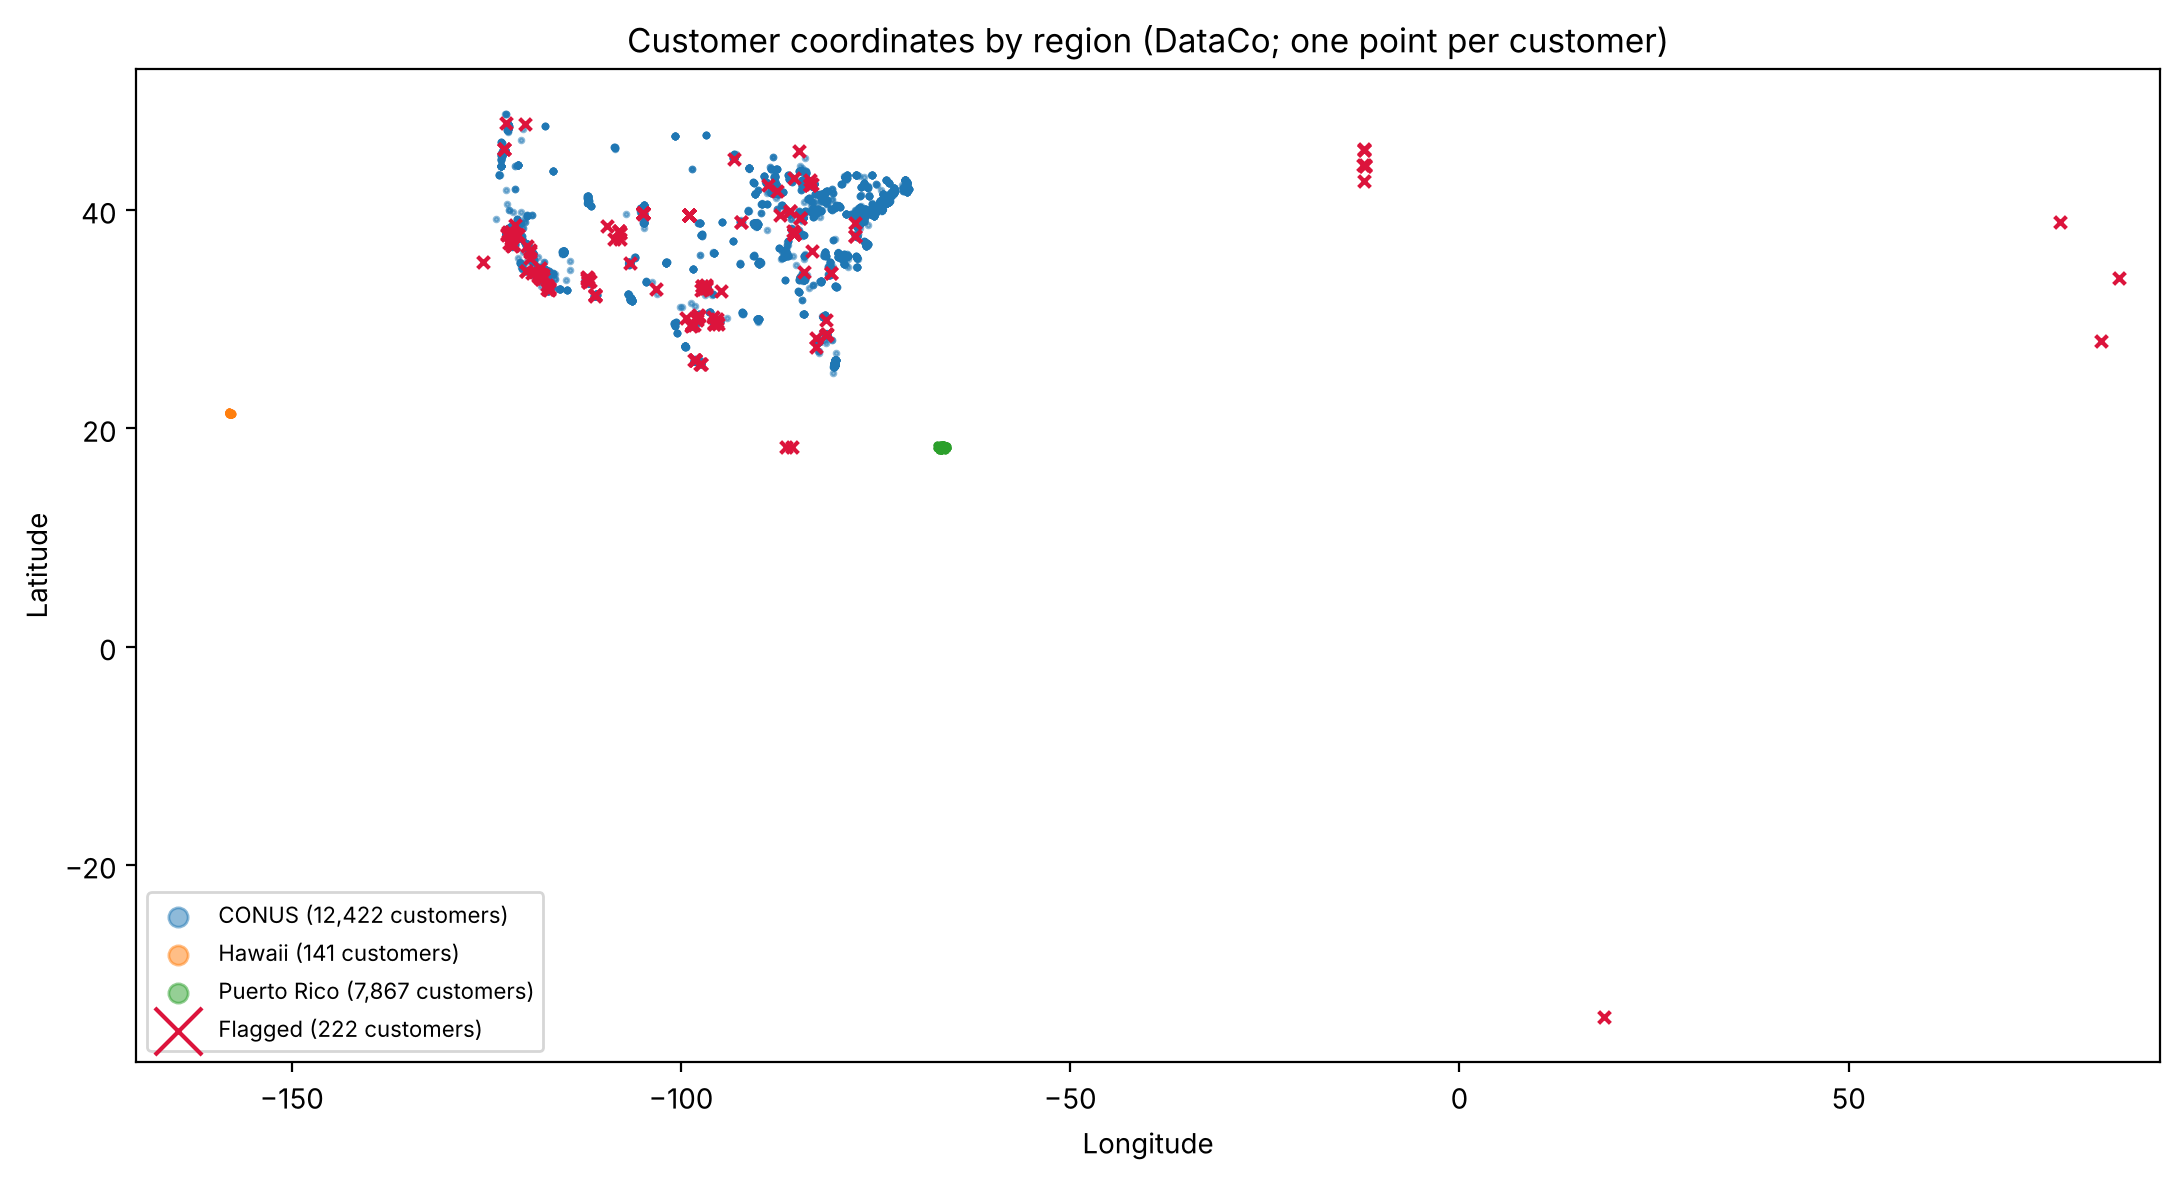

In [5]:
df = load_raw_orders(drop_pii=True)
flags = coordinate_flags(df)  # per-record flags
cust = flags.drop_duplicates('Customer Id').rename(columns={'any_flag': 'flagged'})
fig, ax = plt.subplots(figsize=(11, 6))
for reg, g in cust[~cust.flagged].groupby('region'):
    ax.scatter(g.Longitude, g.Latitude, s=3, alpha=.5, label=f'{reg} ({len(g):,} customers)')
f = cust[cust.flagged]
ax.scatter(f.Longitude, f.Latitude, s=18, marker='x', c='crimson', label=f'Flagged ({len(f):,} customers)')
ax.set_xlim(-170, 90); ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('Customer coordinates by region (DataCo; one point per customer)')
ax.legend(markerscale=4, fontsize=8); fig.tight_layout()
fig.savefig('reports/figures/phase1_customer_coordinates.png', dpi=150); plt.show()

## Monthly volume and the 2017-10 structural break

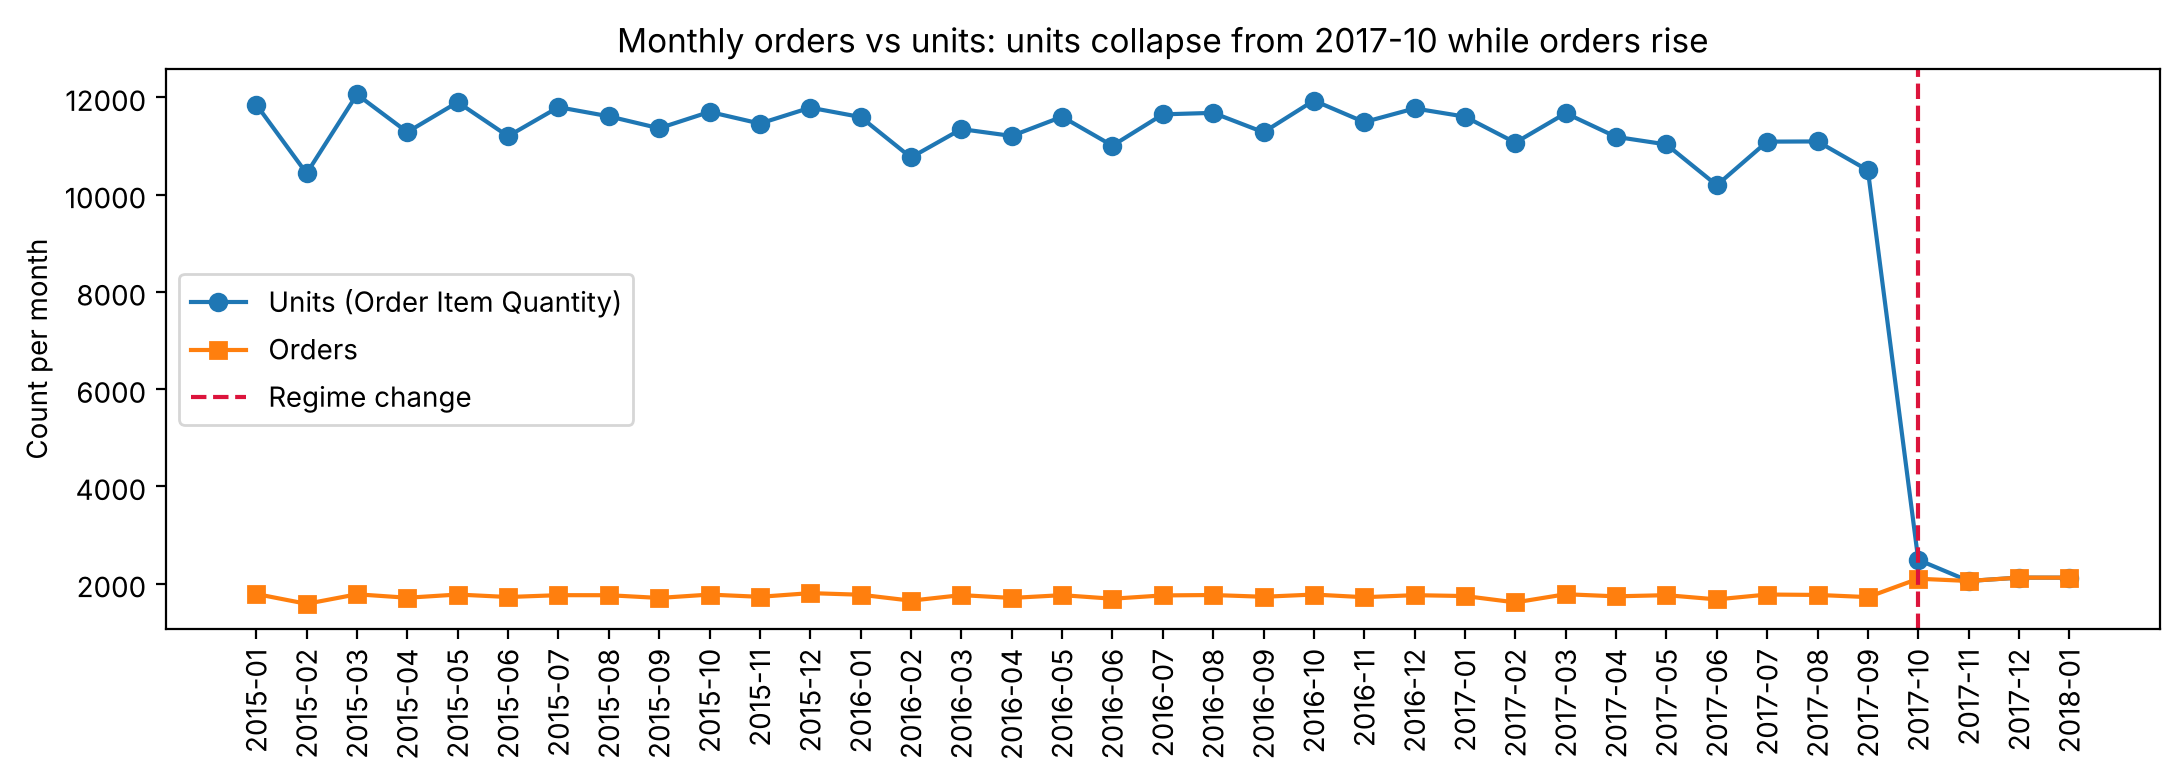

,month,rows,orders,units,items_per_order,n_markets,n_categories,conus_orders
0,2015-01,5322,1787,11854,2.978,1,24,1101
1,2015-02,4729,1585,10438,2.984,1,24,977
2,2015-03,5362,1781,12062,3.011,1,24,1079
3,2015-04,5126,1710,11287,2.998,1,24,1039
4,2015-05,5357,1776,11902,3.016,2,24,1099
5,2015-06,5134,1725,11203,2.976,1,24,1019
6,2015-07,5299,1763,11800,3.006,1,24,1064
7,2015-08,5273,1762,11612,2.993,1,24,1075
8,2015-09,5140,1706,11366,3.013,1,24,1070
9,2015-10,5302,1775,11703,2.987,2,24,1083


In [6]:
m = r.monthly
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(m.month, m.units, marker='o', label='Units (Order Item Quantity)')
ax1.plot(m.month, m.orders, marker='s', label='Orders')
ax1.axvline('2017-10', color='crimson', ls='--', label='Regime change')
ax1.set_ylabel('Count per month'); ax1.tick_params(axis='x', rotation=90); ax1.legend()
ax1.set_title('Monthly orders vs units: units collapse from 2017-10 while orders rise')
fig.tight_layout(); fig.savefig('reports/figures/phase1_monthly_volume.png', dpi=150); plt.show()
m

## Outlier screen

In [7]:
r.outliers

,level,column,min,q1,median,q3,max,lower_fence,upper_fence,outliers,outlier_pct
0,order-item,Order Item Quantity,1.00000,1.000000,1.000000,3.000000,5.000000,-2.000000,6.000000,0,0.000
1,order-item,Sales,9.99000,119.980003,199.919998,299.950012,1999.989990,-149.975010,569.905025,488,0.270
2,order-item,Order Item Total,7.49000,104.379997,163.990005,247.399994,1939.989990,-110.149998,461.929989,1943,1.076
3,order-item,Order Item Product Price,9.99000,50.000000,59.990002,199.990005,1999.989990,-174.985008,424.975014,2048,1.135
4,order-item,Order Item Discount Rate,0.00000,0.040000,0.100000,0.160000,0.250000,-0.140000,0.340000,0,0.000
5,order-item,Order Profit Per Order,-4274.97998,7.000000,31.520000,64.800003,911.799988,-79.700005,151.500008,18942,10.493
6,order-item,Days for shipping (real),0.00000,2.000000,3.000000,5.000000,6.000000,-2.500000,9.500000,0,0.000
7,order,n_items,1.00000,1.000000,3.000000,4.000000,5.000000,-3.500000,8.500000,0,0.000
8,order,units,1.00000,2.000000,5.000000,9.000000,24.000000,-8.500000,19.500000,89,0.135
9,order,sales,9.99000,265.957504,504.890008,799.950028,3449.909988,-535.031282,1600.938813,152,0.231
